# Predição de AVC — APS2: Modelagem

**Aluno:** Matheus Henrique Pereira Borba · **Entrega (APS2):** 27/10/2026

**Dataset:** [Stroke Prediction Dataset](https://www.kaggle.com/datasets/fedesoriano/stroke-prediction-dataset) (Kaggle, fedesoriano)

Seção 1 da APS2: seleção, ajuste e comparação dos modelos, mudança no pipeline e curva de aprendizado. A avaliação no teste, a interpretação e a discussão crítica estão no notebook 04. Todo este notebook usa **somente o treino**.

## Setup

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score, precision_recall_curve, precision_score, recall_score
from sklearn.model_selection import (FixedThresholdClassifier, GridSearchCV, RandomizedSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict, cross_validate, learning_curve)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110})

AZUL, LARANJA, VIOLETA, CINZA = "#2a78d6", "#eb6834", "#4a3aa7", "#898781"
CORES_MODELO = {"Dummy": CINZA, "Regressão logística": AZUL, "Random Forest": VIOLETA}

TARGET = "stroke"
NUM_COLS = ["age", "avg_glucose_level", "bmi"]
BIN_COLS = ["hypertension", "heart_disease"]
CAT_COLS = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]

## Carregamento

Lê o split salvo pelo notebook 01. Se ele não existir, refaz o mesmo split a partir do Kaggle.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
MODELS = ROOT / "models"
MODELS.mkdir(exist_ok=True)

if (PROCESSED / "train.csv").exists():
    train = pd.read_csv(PROCESSED / "train.csv")
else:
    import kagglehub
    from sklearn.model_selection import train_test_split
    df = pd.read_csv(Path(kagglehub.dataset_download("fedesoriano/stroke-prediction-dataset")) / "healthcare-dataset-stroke-data.csv")
    df = df.drop(columns="id").query("gender != 'Other'")
    train, test = train_test_split(df, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)
    PROCESSED.mkdir(parents=True, exist_ok=True)
    train.to_csv(PROCESSED / "train.csv", index=False)
    test.to_csv(PROCESSED / "test.csv", index=False)

X_train, y_train = train.drop(columns=TARGET), train[TARGET]
print(f"treino {X_train.shape}, {y_train.sum()} casos de AVC ({y_train.mean():.1%})")

treino (4087, 10), 199 casos de AVC (4.9%)


## Pipeline da APS1

O pré-processador é o mesmo do notebook 02, sem alterações: imputação do IMC pela mediana com indicador de ausência, log na glicose, limite de 60 no IMC, one-hot nas categóricas e padronização das contínuas. A novidade é que ele vira o primeiro passo de um `Pipeline` com o modelo. Assim, em cada dobra da validação cruzada, medianas, médias, desvios e categorias são reaprendidos só com a parte de treino da dobra, e a validação nunca contamina o pré-processamento.

In [3]:
log = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
limitar = FunctionTransformer(np.clip, kw_args={"a_min": None, "a_max": 60}, feature_names_out="one-to-one")


def criar_preprocessador(categoricas=CAT_COLS):
    """Pré-processador do notebook 02; `categoricas` permite testar a mudança da seção 1.5."""
    return ColumnTransformer([
        ("idade", StandardScaler(), ["age"]),
        ("glicose", make_pipeline(log, StandardScaler()), ["avg_glucose_level"]),
        ("imc", make_pipeline(limitar, SimpleImputer(strategy="median"), StandardScaler()), ["bmi"]),
        ("imc_ausente", MissingIndicator(), ["bmi"]),
        ("binarias", "passthrough", BIN_COLS),
        ("categoricas", OneHotEncoder(drop="if_binary", handle_unknown="ignore", sparse_output=False), categoricas),
    ], verbose_feature_names_out=False).set_output(transform="pandas")


def criar_pipeline(modelo, categoricas=CAT_COLS):
    """Pré-processamento e modelo num único objeto: a validação cruzada refaz o pré-processamento em cada dobra."""
    return Pipeline([("prep", criar_preprocessador(categoricas)), ("modelo", modelo)])


criar_pipeline(LogisticRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('idade', ...), ('glicose', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_

# Seção 1 — Seleção e implementação dos modelos

### 1.1 Métrica de desempenho e estratégia de validação

**Métrica: PR-AUC (average precision).** É a área sob a curva precisão-recall da classe AVC. Motivos:

- com 4,9% de positivos, a acurácia não serve: prever sempre "sem AVC" acerta 95,1% (tarefa 1.6 da APS1);
- não depende de limiar: mede se o modelo ordena os pacientes com AVC acima dos demais, e o limiar é escolhido depois (seção 1.7), com critério clínico;
- foca na classe rara. A ROC-AUC usa a taxa de falsos positivos, cujo denominador são os ~3.900 negativos, e por isso pode parecer alta mesmo quando a maioria dos alertas é falsa (Saito & Rehmsmeier, 2015). Ela é reportada como métrica secundária;
- tem referência clara: um modelo sem informação tem PR-AUC igual à prevalência (0,049).

**Validação: 5 dobras estratificadas, repetidas 3 vezes (15 avaliações).** A estratificação garante cerca de 40 casos de AVC em cada dobra de validação. Com tão poucos positivos a nota de uma dobra varia muito, e repetir a divisão com outras sementes reduz essa variância. O mesmo objeto (`cv_busca`) é usado em todas as buscas, então todos os modelos são avaliados nas mesmas dobras.

Para comparar modelos já ajustados, um segundo esquema (`cv_comparacao`, 5 × 5 com outra semente) avalia em dobras que a busca não viu. A melhor nota de uma busca é otimista, porque é o máximo entre muitas combinações (Cawley & Talbot, 2010).

In [4]:
METRICA = "average_precision"
cv_busca = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
cv_comparacao = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7)

positivos = [int(y_train.iloc[val].sum()) for _, val in StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE).split(X_train, y_train)]
print(f"Casos de AVC por dobra de validação: {positivos}")
print(f"PR-AUC de um modelo sem informação = prevalência = {y_train.mean():.3f}")

Casos de AVC por dobra de validação: [40, 40, 39, 40, 40]
PR-AUC de um modelo sem informação = prevalência = 0.049


### 1.2 Modelos com hiperparâmetros padrão

Os três modelos pedidos, primeiro com os hiperparâmetros padrão do scikit-learn:

- **Dummy** (`strategy="prior"`): prevê para todo paciente a probabilidade igual à prevalência do treino. É o piso: qualquer modelo útil precisa superá-lo.
- **Regressão logística**: modelo linear nos log-odds, referência em modelos de risco clínico e com coeficientes interpretáveis. O padrão do scikit-learn já tem regularização L2 com C = 1.
- **Random Forest**: ensemble de árvores treinadas em amostras bootstrap (Breiman, 2001). Captura não linearidades e interações (glicose alta pesa mais em idosos, tarefa 3.3 da APS1) sem precisar criá-las à mão, e reduz a variância de uma árvore isolada tirando a média de muitas.

In [5]:
modelos_base = {
    "Dummy": DummyClassifier(strategy="prior"),
    "Regressão logística": LogisticRegression(max_iter=5000),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
}


def avaliar(pipeline, cv=cv_busca):
    r = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"pr_auc": METRICA, "roc_auc": "roc_auc"},
                       return_train_score=True, n_jobs=-1)
    return pd.Series({"PR-AUC treino": r["train_pr_auc"].mean(), "PR-AUC validação": r["test_pr_auc"].mean(),
                      "desvio": r["test_pr_auc"].std(), "ROC-AUC validação": r["test_roc_auc"].mean()})


pd.DataFrame({nome: avaliar(criar_pipeline(modelo)) for nome, modelo in modelos_base.items()}).T.round(3)

,PR-AUC treino,PR-AUC validação,desvio,ROC-AUC validação
Dummy,0.049,0.049,0.000,0.500
Regressão logística,0.237,0.227,0.040,0.851
Random Forest,1.000,0.180,0.025,0.806


A regressão logística já chega a PR-AUC 0,227, 4,6 vezes o Dummy, e treino e validação ficam próximos (0,237 e 0,227): não há sobreajuste. A Random Forest padrão faz o oposto: PR-AUC 1,000 no treino e 0,180 na validação. Com árvores sem limite de profundidade e folhas de um paciente, cada árvore decora o treino, e com só 199 casos de AVC o que ela decora é em boa parte ruído. A seleção de hiperparâmetros a seguir ataca esse problema.

### 1.3 Seleção de hiperparâmetros

#### Regressão logística — GridSearchCV

Hiperparâmetros buscados, com o solver `saga`, o único que aceita as três penalidades:

| Hiperparâmetro | Valores | Por quê |
|---|---|---|
| C | 11 valores de 0,001 a 100, em escala log | é o inverso da força da regularização; a escala log vai de modelos quase constantes a quase sem penalidade |
| l1_ratio | 0 (L2), 0,5 (elastic net), 1 (L1) | L2 encolhe todos os coeficientes; L1 pode zerá-los, fazendo seleção de features (Tibshirani, 1996); elastic net combina os dois (Zou & Hastie, 2005) |
| class_weight | nenhum, balanceado | o balanceado dá a cada AVC peso ~20 vezes maior, alternativa a reamostrar os dados |

São 66 combinações. Como a regressão logística treina em menos de um segundo, a busca exaustiva (GridSearchCV) é viável.

In [6]:
grade_logistica = {
    "modelo__C": np.logspace(-3, 2, 11),
    "modelo__l1_ratio": [0, 0.5, 1],
    "modelo__class_weight": [None, "balanced"],
}
busca_logistica = GridSearchCV(criar_pipeline(LogisticRegression(solver="saga", max_iter=10_000)), grade_logistica,
                               scoring=METRICA, cv=cv_busca, n_jobs=-1).fit(X_train, y_train)

print(f"{len(busca_logistica.cv_results_['params'])} combinações × {cv_busca.get_n_splits()} dobras")
print("Melhor:", busca_logistica.best_params_, f"PR-AUC {busca_logistica.best_score_:.3f}")

66 combinações × 15 dobras
Melhor: {'modelo__C': np.float64(0.31622776601683794), 'modelo__class_weight': None, 'modelo__l1_ratio': 1} PR-AUC 0.229


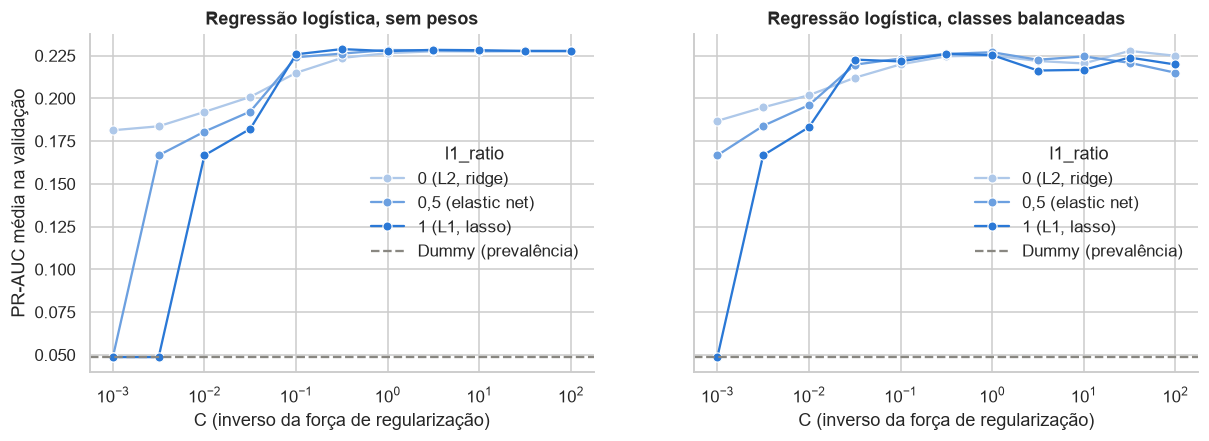

In [7]:
resultados_lr = pd.DataFrame(busca_logistica.cv_results_)
resultados_lr["pesos"] = resultados_lr["param_modelo__class_weight"].fillna("nenhum").map({"nenhum": "sem pesos", "balanced": "classes balanceadas"})
resultados_lr["l1_ratio"] = resultados_lr["param_modelo__l1_ratio"].map({0: "0 (L2, ridge)", 0.5: "0,5 (elastic net)", 1: "1 (L1, lasso)"})

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (pesos, grupo) in zip(axes, resultados_lr.groupby("pesos", sort=False)):
    sns.lineplot(data=grupo, x="param_modelo__C", y="mean_test_score", hue="l1_ratio", marker="o",
                 palette=sns.light_palette(AZUL, 4)[1:], ax=ax)
    ax.axhline(y_train.mean(), color=CINZA, ls="--", label="Dummy (prevalência)")
    ax.set(xscale="log", title=f"Regressão logística, {pesos}", xlabel="C (inverso da força de regularização)", ylabel="PR-AUC média na validação")
    ax.legend(title="l1_ratio")
plt.show()

A PR-AUC só cai com regularização forte (C ≤ 0,03): os coeficientes encolhem até o modelo perder a ordenação, e com L1 e C = 0,001 todos são zerados e o modelo vira o Dummy. De C = 0,1 em diante a curva é plana: 4.087 pacientes para 18 features é pouco risco de sobreajuste, então há pouco para a regularização corrigir. O melhor ponto (L1, C = 0,32, sem pesos) fica só 0,002 acima do padrão, dentro do ruído. Pesar as classes não ajuda: o peso muda a escala das probabilidades, mas quase não muda a ordem dos pacientes, que é o que a PR-AUC mede.

#### Random Forest — RandomizedSearchCV

| Hiperparâmetro | Valores | Por quê |
|---|---|---|
| max_depth | 3, 5, 8, 12, sem limite | limita o quanto cada árvore pode decorar o treino |
| min_samples_leaf | 1 a 80 | folhas maiores dão probabilidades menos ruidosas: com 4,9% de AVC, uma folha de 20 pacientes tem em média 1 caso |
| max_features | raiz, 30%, 50% ou 100% das features | quanto menor, mais diferentes as árvores entre si e maior o ganho da média |
| class_weight | nenhum, balanced, balanced_subsample | mesma ideia da regressão logística; o subsample recalcula os pesos em cada amostra bootstrap |

O número de árvores fica fixo em 300: mais árvores não pioram a floresta, só deixam o treino mais lento (Breiman, 2001). São 360 combinações, cada uma com 15 ajustes de 300 árvores; a busca aleatória (RandomizedSearchCV) testa 40. Quando poucos hiperparâmetros realmente importam, 40 sorteios cobrem bem o espaço com uma fração do custo (Bergstra & Bengio, 2012).

In [8]:
espaco_rf = {
    "modelo__n_estimators": [300],
    "modelo__max_depth": [3, 5, 8, 12, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 40, 80],
    "modelo__max_features": ["sqrt", 0.3, 0.5, 1.0],
    "modelo__class_weight": [None, "balanced", "balanced_subsample"],
}


def buscar_rf(categoricas=CAT_COLS):
    busca = RandomizedSearchCV(criar_pipeline(RandomForestClassifier(random_state=RANDOM_STATE), categoricas), espaco_rf,
                               n_iter=40, scoring=METRICA, cv=cv_busca, n_jobs=-1, random_state=RANDOM_STATE)
    return busca.fit(X_train, y_train)


busca_rf = buscar_rf()
print(f"40 de {np.prod([len(v) for v in espaco_rf.values()])} combinações × {cv_busca.get_n_splits()} dobras")
print("Melhor:", busca_rf.best_params_, f"PR-AUC {busca_rf.best_score_:.3f}")

40 de 360 combinações × 15 dobras
Melhor: {'modelo__n_estimators': 300, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 5, 'modelo__class_weight': None} PR-AUC 0.254


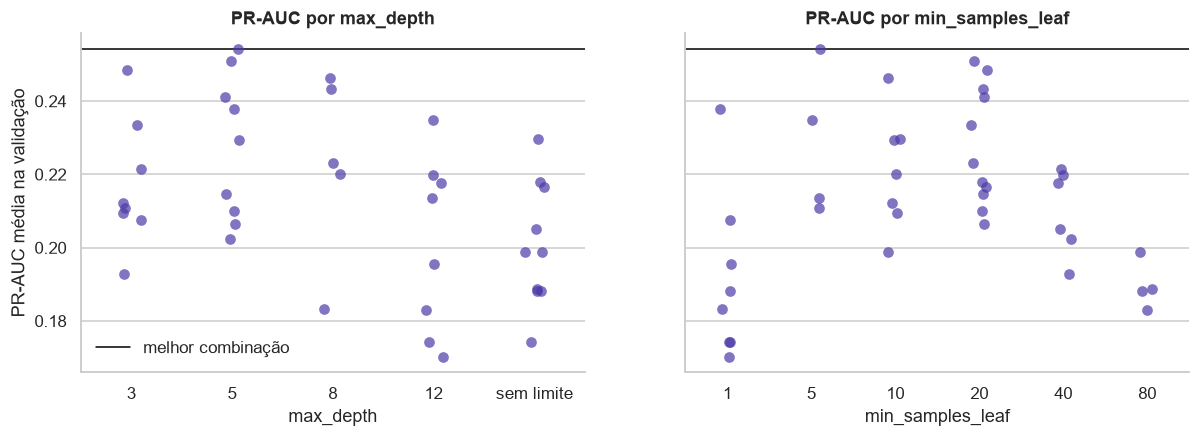

,param_modelo__min_samples_leaf,param_modelo__max_features,param_modelo__max_depth,param_modelo__class_weight,mean_test_score,std_test_score
28,5,sqrt,5,NaN,0.254,0.036
35,20,0.5,5,NaN,0.251,0.044
6,20,0.5,3,NaN,0.248,0.045
4,10,0.3,8,NaN,0.246,0.033
7,20,0.3,8,NaN,0.243,0.031


In [9]:
resultados_rf = pd.DataFrame(busca_rf.cv_results_)
resultados_rf["max_depth"] = resultados_rf["param_modelo__max_depth"].fillna("sem limite").astype(str)
resultados_rf["min_samples_leaf"] = resultados_rf["param_modelo__min_samples_leaf"].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (col, ordem) in zip(axes, [("max_depth", ["3", "5", "8", "12", "sem limite"]), ("min_samples_leaf", [1, 5, 10, 20, 40, 80])]):
    sns.stripplot(data=resultados_rf, x=col, y="mean_test_score", order=ordem, color=VIOLETA, size=7, alpha=0.7, ax=ax)
    ax.axhline(busca_rf.best_score_, color="black", lw=1, label="melhor combinação")
    ax.set(title=f"PR-AUC por {col}", xlabel=col, ylabel="PR-AUC média na validação")
axes[0].legend()
plt.show()

colunas = [c for c in resultados_rf if c.startswith("param_") and c != "param_modelo__n_estimators"]
resultados_rf.sort_values("rank_test_score")[colunas + ["mean_test_score", "std_test_score"]].head(5).round(3)

A melhor combinação usa árvores rasas (profundidade 5), folhas com pelo menos 5 pacientes, raiz quadrada das features em cada divisão e nenhum peso de classe: PR-AUC 0,254. O padrão aparece no gráfico: árvores sem limite ou folhas de 1 paciente ficam embaixo, e as cinco melhores combinações têm profundidade de 3 a 8. É a correção do sobreajuste da seção 1.2. Pesar as classes não aparece entre as melhores, pelo mesmo motivo da regressão logística.

### 1.4 Comparação dos modelos

Os cinco candidatos (os três modelos, dois deles antes e depois da busca) são reavaliados em `cv_comparacao`: 25 dobras novas, que não foram usadas para escolher nada.

In [10]:
candidatos = {
    ("Dummy", "padrão"): criar_pipeline(DummyClassifier(strategy="prior")),
    ("Regressão logística", "padrão"): criar_pipeline(LogisticRegression(max_iter=5000)),
    ("Regressão logística", "ajustada"): busca_logistica.best_estimator_,
    ("Random Forest", "padrão"): criar_pipeline(RandomForestClassifier(random_state=RANDOM_STATE)),
    ("Random Forest", "ajustada"): busca_rf.best_estimator_,
}
comparacao = pd.DataFrame({nome: avaliar(pipe, cv_comparacao) for nome, pipe in candidatos.items()}).T
comparacao.index.names = ["modelo", "hiperparâmetros"]
comparacao.round(3)

PR-AUC treino  PR-AUC validação  desvio  \
modelo              hiperparâmetros                                            
Dummy               padrão                   0.049             0.049   0.000   
Regressão logística padrão                   0.237             0.225   0.047   
                    ajustada                 0.232             0.225   0.045   
Random Forest       padrão                   1.000             0.186   0.041   
                    ajustada                 0.455             0.258   0.059   

                                     ROC-AUC validação  
modelo              hiperparâmetros                     
Dummy               padrão                       0.500  
Regressão logística padrão                       0.849  
                    ajustada                     0.851  
Random Forest       padrão                       0.814  
                    ajustada                     0.851

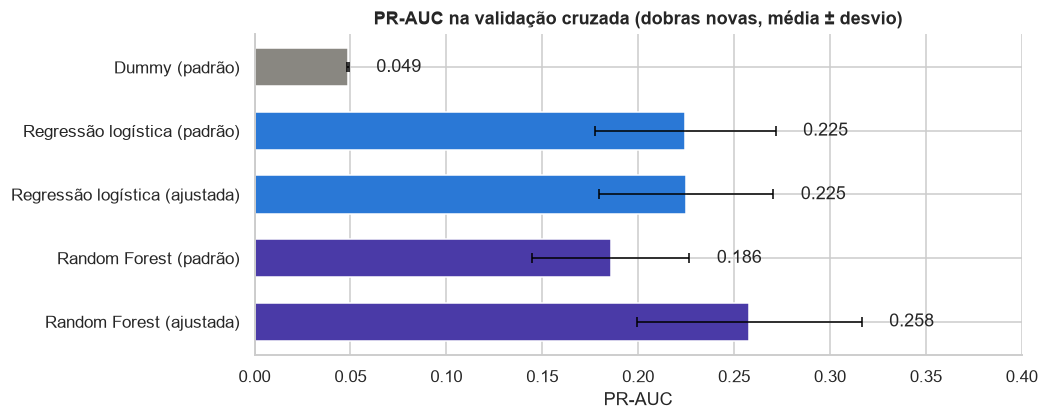

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.8))
rotulos = [f"{m} ({h})" for m, h in comparacao.index]
ax.barh(rotulos, comparacao["PR-AUC validação"], xerr=comparacao["desvio"], height=0.6,
        color=[CORES_MODELO[m] for m, _ in comparacao.index], error_kw={"ecolor": "black", "capsize": 3, "lw": 1})
ax.bar_label(ax.containers[1], fmt="%.3f", padding=18)
ax.invert_yaxis()
ax.set(title="PR-AUC na validação cruzada (dobras novas, média ± desvio)", xlabel="PR-AUC", xlim=(0, 0.4))
plt.show()

Em dobras novas, a **Random Forest ajustada é o melhor modelo**: PR-AUC 0,258, contra 0,225 da regressão logística e 0,049 do Dummy. Em ROC-AUC as duas empatam (0,851); a PR-AUC, que olha para a classe rara, é que as separa.

- A busca rendeu +0,072 para a floresta (de 0,186) e nada para a regressão logística, coerente com os gráficos: só a floresta padrão estava sobreajustada.
- A vantagem da floresta sobre a regressão (0,033) é menor que o desvio entre dobras (~0,05): existe na média, mas é modesta.
- O treino da floresta ajustada (0,455) ainda fica bem acima da validação: há sobreajuste residual, analisado na curva de aprendizado (seção 1.6).

### 1.5 Mudança no pipeline: remoção de features sem sinal próprio

**Proposta:** remover três variáveis categóricas que a APS1 mostrou não terem sinal próprio.

| Variável | Evidência na APS1 |
|---|---|
| gender | V de Cramér 0,010, p = 0,53: nenhuma associação com o AVC |
| Residence_type | V de Cramér 0,017, p = 0,28: nenhuma associação com o AVC |
| work_type | a associação some dentro de cada faixa etária: é um proxy de idade ("children" é literalmente idade; "Never_worked" tem 16 pacientes, nenhum com AVC) |

O estado civil fica: também é confundido pela idade, mas acima dos 60 anos ainda mostra diferença (20,0% contra 12,7%). O tabagismo fica, porque a categoria desconhecida carrega informação.

**Por que deve ajudar a Random Forest.** Com `max_features="sqrt"`, cada divisão sorteia só 4 das 18 colunas. As 7 colunas dessas variáveis (gênero, residência e 5 de trabalho) são 39% das features, então muitas divisões só têm ruído ou proxies de idade como opção, e com 199 casos de AVC cada divisão desperdiçada custa caro. Com 11 colunas, a raiz sorteia 3, e todas as candidatas têm sinal.

**Ablação.** Antes da nova busca, a tabela compara remoções crescentes com os hiperparâmetros da seção 1.3 fixos, para mostrar que a escolha não é arbitrária.

In [12]:
categoricas_novas = ["ever_married", "smoking_status"]
rf_fixo = RandomForestClassifier(random_state=RANDOM_STATE).set_params(
    **{k.removeprefix("modelo__"): v for k, v in busca_rf.best_params_.items()})

variantes = {
    "pipeline da APS1 (18 features)": CAT_COLS,
    "− gender, Residence_type": ["ever_married", "work_type", "smoking_status"],
    "− gender, Residence_type, work_type (proposta)": categoricas_novas,
    "− gender, Residence_type, work_type, ever_married": ["smoking_status"],
}
pd.DataFrame({nome: avaliar(criar_pipeline(rf_fixo, cats))[["PR-AUC validação", "desvio", "ROC-AUC validação"]]
              for nome, cats in variantes.items()}).T.round(3)

,PR-AUC validação,desvio,ROC-AUC validação
pipeline da APS1 (18 features),0.254,0.036,0.850
"− gender, Residence_type",0.261,0.038,0.852
"− gender, Residence_type, work_type (proposta)",0.264,0.034,0.853
"− gender, Residence_type, work_type, ever_married",0.259,0.035,0.853


Cada remoção da proposta melhora a PR-AUC (0,254 → 0,261 → 0,264), e remover também o estado civil piora (0,259). Confirma a APS1: das quatro, o estado civil é a única com algum sinal além da idade. A seguir, a mudança é avaliada com uma nova seleção de hiperparâmetros, com a mesma métrica, o mesmo espaço de busca, o mesmo número de sorteios e as mesmas dobras.

In [13]:
busca_rf_nova = buscar_rf(categoricas_novas)
print("Melhor:", busca_rf_nova.best_params_, f"PR-AUC {busca_rf_nova.best_score_:.3f}")
print(f"Features: {busca_rf_nova.best_estimator_['prep'].get_feature_names_out().size} (eram 18)")

notas = pd.DataFrame({
    "APS1": cross_validate(busca_rf.best_estimator_, X_train, y_train, cv=cv_comparacao, scoring=METRICA, n_jobs=-1)["test_score"],
    "nova": cross_validate(busca_rf_nova.best_estimator_, X_train, y_train, cv=cv_comparacao, scoring=METRICA, n_jobs=-1)["test_score"],
})
notas["diferença"] = notas["nova"] - notas["APS1"]
pd.DataFrame({
    "PR-AUC na busca (cv_busca)": [busca_rf.best_score_, busca_rf_nova.best_score_, busca_rf_nova.best_score_ - busca_rf.best_score_],
    "PR-AUC em dobras novas (cv_comparacao)": notas.mean().to_numpy(),
}, index=["Random Forest, pipeline da APS1", "Random Forest, pipeline novo", "diferença"]).round(4)

Melhor: {'modelo__n_estimators': 300, 'modelo__min_samples_leaf': 5, 'modelo__max_features': 'sqrt', 'modelo__max_depth': 5, 'modelo__class_weight': None} PR-AUC 0.264
Features: 11 (eram 18)


,PR-AUC na busca (cv_busca),PR-AUC em dobras novas (cv_comparacao)
"Random Forest, pipeline da APS1",0.2542,0.2579
"Random Forest, pipeline novo",0.2637,0.2688
diferença,0.0095,0.0108


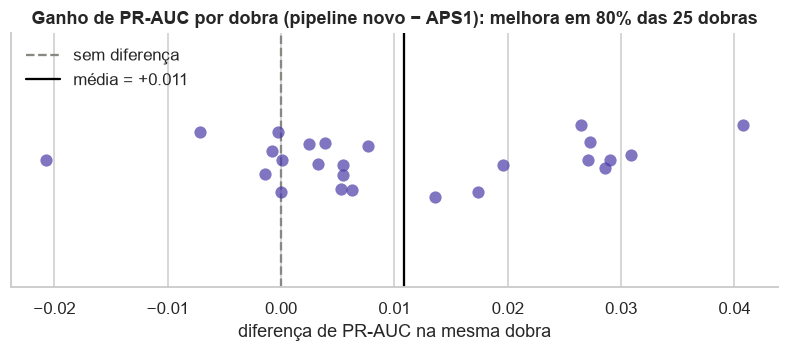

In [14]:
fig, ax = plt.subplots(figsize=(9, 3))
sns.stripplot(x=notas["diferença"], color=VIOLETA, size=8, alpha=0.7, jitter=0.15, ax=ax)
ax.axvline(0, color=CINZA, ls="--", label="sem diferença")
ax.axvline(notas["diferença"].mean(), color="black", label=f"média = {notas['diferença'].mean():+.3f}")
ax.set(title=f"Ganho de PR-AUC por dobra (pipeline novo − APS1): melhora em {(notas['diferença'] > 0).mean():.0%} das {len(notas)} dobras",
       xlabel="diferença de PR-AUC na mesma dobra")
ax.legend(loc="upper left")
plt.show()

A nova busca chega aos mesmos hiperparâmetros (profundidade 5, folhas de 5, raiz das features), e a PR-AUC sobe de 0,254 para 0,264 nas dobras da busca e de 0,258 para 0,269 nas dobras novas: ganho de cerca de 0,01 (4% relativos) nos dois esquemas. Como os dois pipelines são avaliados nas mesmas 25 dobras, a comparação é pareada, e o pipeline novo vence em 80% delas: o ganho não é sorte de uma divisão.

O ganho é pequeno, como se espera de uma mudança que só remove ruído. Os benefícios extras são um modelo com 11 features em vez de 18, mais simples de explicar e de usar (três campos a menos para coletar). **O pipeline novo é adotado, e a Random Forest com ele é o modelo final.**

### 1.6 Curva de aprendizado do melhor modelo

A curva treina o modelo final com frações crescentes do treino (10% a 100%) e mede a PR-AUC nas mesmas 15 dobras de validação. Responde a duas perguntas: o modelo sofre de viés ou de variância, e mais dados ajudariam?

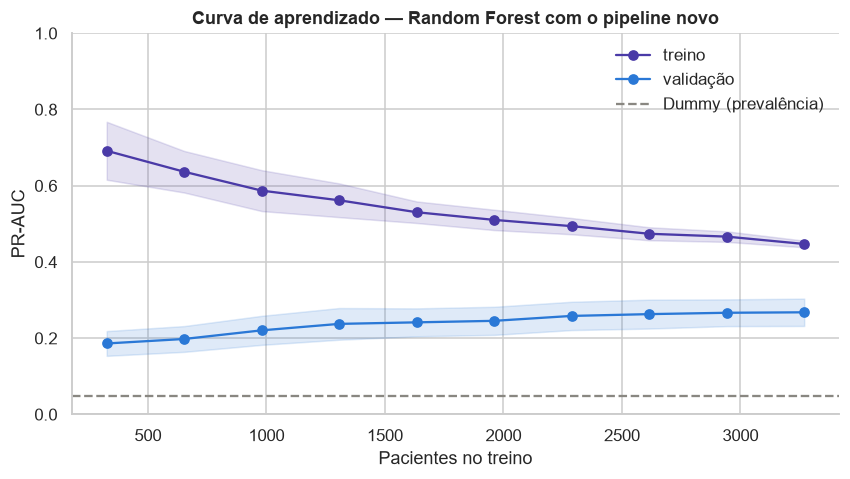

,pacientes,casos de AVC (aprox.),PR-AUC treino,PR-AUC validação
0,326,16,0.692,0.186
2,980,48,0.587,0.221
4,1634,80,0.530,0.242
6,2288,111,0.494,0.258
9,3269,159,0.447,0.268


In [15]:
melhor = busca_rf_nova.best_estimator_
tamanhos, nota_treino, nota_validacao = learning_curve(melhor, X_train, y_train, train_sizes=np.linspace(0.1, 1, 10), cv=cv_busca,
                                                       scoring=METRICA, n_jobs=-1, shuffle=True, random_state=RANDOM_STATE)

fig, ax = plt.subplots(figsize=(9, 4.5))
for notas_curva, nome, cor in [(nota_treino, "treino", VIOLETA), (nota_validacao, "validação", AZUL)]:
    media, desvio = notas_curva.mean(axis=1), notas_curva.std(axis=1)
    ax.plot(tamanhos, media, marker="o", color=cor, label=nome)
    ax.fill_between(tamanhos, media - desvio, media + desvio, color=cor, alpha=0.15)
ax.axhline(y_train.mean(), color=CINZA, ls="--", label="Dummy (prevalência)")
ax.set(title="Curva de aprendizado — Random Forest com o pipeline novo", xlabel="Pacientes no treino", ylabel="PR-AUC", ylim=(0, 1))
ax.legend()
plt.show()

pd.DataFrame({"pacientes": tamanhos, "casos de AVC (aprox.)": (tamanhos * y_train.mean()).round().astype(int),
              "PR-AUC treino": nota_treino.mean(axis=1), "PR-AUC validação": nota_validacao.mean(axis=1)}).iloc[[0, 2, 4, 6, 9]].round(3)

- **Treino** cai de 0,69 para 0,45: com poucos pacientes, a floresta decora boa parte dos casos de AVC; com mais, isso fica difícil.
- **Validação** sobe de 0,19 para 0,27 e ainda não estabilizou: de 70% para 100% dos dados ainda ganha 0,01.
- **A distância entre as curvas** cai de 0,51 para 0,18, mas continua grande: o problema é variância (sobreajuste residual), não viés.

Conclusão: o modelo é limitado pela quantidade de casos de AVC, não pela capacidade. Com 100% do treino, cada dobra de treino tem só ~160 casos; mais dados, principalmente mais casos positivos, devem melhorar a validação. Aumentar a complexidade não é o caminho: a busca já mostrou que árvores mais profundas pioram.

### 1.7 Limiar de decisão

A PR-AUC avalia a ordenação; para usar o modelo é preciso um limiar acima do qual o paciente é sinalizado. O padrão de 0,5 não serve aqui: com 4,9% de AVC, a floresta quase nunca prevê probabilidades tão altas.

**Critério: maximizar o F2.** O F-beta com β = 2 combina precisão e recall dando ao recall peso duas vezes maior (van Rijsbergen, 1979). A escolha é clínica: um falso negativo é um paciente de risco que não é encaminhado, e um falso positivo é um exame a mais. Em triagem, deixar passar um caso custa mais que um falso alarme.

**Sem vazamento:** o limiar é escolhido com previsões fora da dobra do treino (cada paciente recebe a probabilidade de um modelo que não o viu). O teste continua intocado.

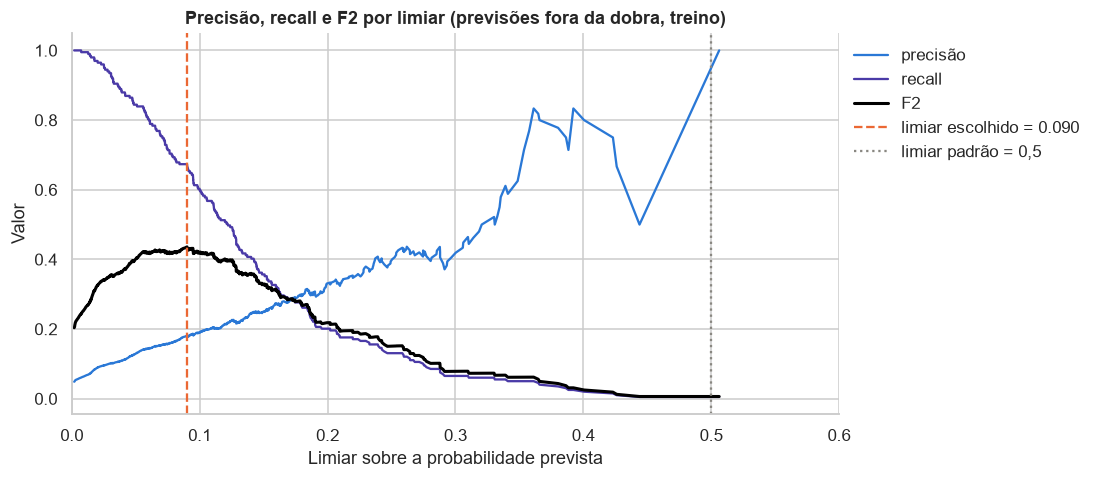

,limiar,alertas (% do treino),precisão,recall,F1,F2
"padrão (0,5)",0.500,0.024,1.000,0.005,0.010,0.006
máximo F1,0.125,10.595,0.226,0.492,0.310,0.399
máximo F2 (escolhido),0.090,18.131,0.181,0.673,0.285,0.436


In [16]:
proba_oof = cross_val_predict(melhor, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
                              method="predict_proba", n_jobs=-1)[:, 1]
precisao, recall, limiares = precision_recall_curve(y_train, proba_oof)
precisao, recall = precisao[:-1], recall[:-1]
f2 = 5 * precisao * recall / np.where(4 * precisao + recall == 0, 1, 4 * precisao + recall)
f1 = 2 * precisao * recall / np.where(precisao + recall == 0, 1, precisao + recall)
LIMIAR = float(limiares[f2.argmax()])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(limiares, precisao, color=AZUL, label="precisão")
ax.plot(limiares, recall, color=VIOLETA, label="recall")
ax.plot(limiares, f2, color="black", lw=2, label="F2")
ax.axvline(LIMIAR, color=LARANJA, ls="--", label=f"limiar escolhido = {LIMIAR:.3f}")
ax.axvline(0.5, color=CINZA, ls=":", label="limiar padrão = 0,5")
ax.set(title="Precisão, recall e F2 por limiar (previsões fora da dobra, treino)", xlabel="Limiar sobre a probabilidade prevista", ylabel="Valor", xlim=(0, 0.6))
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

def no_limiar(limiar):
    previsto = proba_oof >= limiar
    return pd.Series({"limiar": limiar, "alertas (% do treino)": previsto.mean() * 100,
                      "precisão": precision_score(y_train, previsto, zero_division=0), "recall": recall_score(y_train, previsto),
                      "F1": fbeta_score(y_train, previsto, beta=1), "F2": fbeta_score(y_train, previsto, beta=2)})


pd.DataFrame({"padrão (0,5)": no_limiar(0.5), "máximo F1": no_limiar(limiares[f1.argmax()]),
              "máximo F2 (escolhido)": no_limiar(LIMIAR)}).T.round(3)

Com 0,5, o modelo quase não sinaliza ninguém (0,02% do treino, recall de 0,5%). O F2 é máximo em 0,090: recall de 67% e precisão de 18%, com 18% dos pacientes sinalizados. Maximizar o F1 levaria a 0,125, com recall de 49%: perderia um a cada dois casos. A curva de F2 é quase plana entre ~0,06 e ~0,12, então o resultado não depende de um ponto exato. Em termos práticos: para encontrar 2 de cada 3 AVCs, o modelo emite cerca de 5,5 alertas por caso verdadeiro.

### 1.8 Modelos salvos

O modelo final é a Random Forest com o pipeline novo dentro de um `FixedThresholdClassifier` com limiar 0,090, reajustado com todo o treino. Ele é salvo com a regressão logística ajustada (usada na interpretação da seção 3) e o Dummy (referência) para o notebook 04. A pasta `models/` não é versionada, como os dados; ela é regenerada ao executar este notebook.

In [17]:
modelo_final = FixedThresholdClassifier(melhor, threshold=LIMIAR, response_method="predict_proba").fit(X_train, y_train)
joblib.dump({
    "modelo_final": modelo_final,
    "logistica": busca_logistica.best_estimator_,
    "dummy": criar_pipeline(DummyClassifier(strategy="prior")).fit(X_train, y_train),
    "comparacao_cv": comparacao,
}, MODELS / "modelos.joblib")

print(f"Salvo em models/modelos.joblib. Limiar do modelo final: {modelo_final.threshold:.3f}")
modelo_final

Salvo em models/modelos.joblib. Limiar do modelo final: 0.090


,"estimator estimator: estimator instanceThe binary classifier, fitted or not, for which we want to optimizethe decision threshold used during `predict`.",Pipeline(step...m_state=42))])
,"threshold threshold: {""auto""} or float, default=""auto""The decision threshold to use when converting posterior probability estimates(i.e. output of `predict_proba`) or decision scores (i.e. output of`decision_function`) into a class label. When `""auto""`, the threshold is setto 0.5 if `predict_proba` is used as `response_method`, otherwise it is set to0 (i.e. the default threshold for `decision_function`).",0.09009067355550361
,"response_method response_method: {""auto"", ""decision_function"", ""predict_proba""}, default=""auto""Methods by the classifier `estimator` corresponding to thedecision function for which we want to find a threshold. It can be:* if `""auto""`, it will try to invoke `""predict_proba""` or `""decision_function""` in that order.* otherwise, one of `""predict_proba""` or `""decision_function""`. If the method is not implemented by the classifier, it will raise an error.",'predict_proba'
,"pos_label pos_label: int, float, bool or str, default=NoneThe label of the positive class. Used to process the output of the`response_method` method. When `pos_label=None`, if `y_true` is in `{-1, 1}` or`{0, 1}`, `pos_label` is set to 1, otherwise an error will be raised.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The class labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimator instanceThe fitted classifier used when predicting.,Pipeline,Pipeline(step...m_state=42))])
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit.","ndarray[object](10,)","['gender','age','hypertension',...,'avg_glucose_level','bmi', 'smoking_status']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit.,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('idade', ...), ('glicose', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature

# Resumo da seção 1

| Etapa | Resultado |
|---|---|
| Métrica | PR-AUC (average precision), adequada à classe rara; ROC-AUC como secundária |
| Dummy | PR-AUC 0,049, igual à prevalência |
| Regressão logística | 0,225 com ou sem busca; a regularização quase não importa (melhor: L1, C = 0,32) |
| Random Forest | de 0,186 para 0,258 com a busca: árvores rasas corrigem o sobreajuste |
| Mudança no pipeline | remover gender, Residence_type e work_type: de 0,258 para 0,269, melhora em 80% das dobras |
| Curva de aprendizado | validação ainda subindo: o modelo é limitado por dados, não por capacidade |
| Limiar | 0,090 (máximo F2): recall de 67% e precisão de 18% no treino |

O notebook 04 avalia esse modelo no teste, interpreta os modelos e discute as limitações.

## Referências

- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *Journal of Machine Learning Research*, 13, 281–305.
- Breiman, L. (2001). Random forests. *Machine Learning*, 45(1), 5–32.
- Cawley, G. C., & Talbot, N. L. C. (2010). On over-fitting in model selection and subsequent selection bias in performance evaluation. *Journal of Machine Learning Research*, 11, 2079–2107.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3), e0118432.
- Tibshirani, R. (1996). Regression shrinkage and selection via the lasso. *Journal of the Royal Statistical Society: Series B*, 58(1), 267–288.
- van Rijsbergen, C. J. (1979). *Information Retrieval* (2ª ed.). Butterworths.
- Zou, H., & Hastie, T. (2005). Regularization and variable selection via the elastic net. *Journal of the Royal Statistical Society: Series B*, 67(2), 301–320.